# B2: cluster-theoretic Newton–Okounkov polytopes
An executable verification at **weight $2\rho$**, in four stages:
1. Generate all seeds and polytopes.
2. Compare combinatorial equivalence.
3. Compare affine unimodular equivalence and verify explicit affine maps.
4. Determine colored exchange-graph automorphisms.

Only the initial matrix and inequalities are input. The graph, polytopes,
classifications and permutations are computed here, without reading a stored
classification. Expected counts are assertions after calculation.

**Start here:** keep finite_type_verification.py beside this notebook and select
the **SageMath** kernel in Jupyter (tested with SageMath 10.8).
The code follows the seed enumeration and tropical-mutation workflow of
[0_functions.ipynb and 1_examples.ipynb](https://github.com/eunjeonglee-math/flag_NOpolytopes).
The shared helper contains the complete, readable implementation.

A first run computes from the initial seed. Local checkpoints allow interrupted
runs to resume. 

**Conventions.** We use Fujita–Oya's $C_2$ coordinates and word $(1,2,1,2)$,
which is the word $(2,1,2,1)$ in $B_2$ numbering.
The long root is $\alpha_1$ in $B_2$ and $\alpha_2$ in $C_2$.
There are two mutable and two frozen coordinates.
Fujita–Oya's mutable-row matrix is
$\varepsilon=\left(\begin{smallmatrix}0&-2&1&0\\1&0&-1&1\end{smallmatrix}\right)$;
our column convention is $B=-\varepsilon^T$.
The principal part is skew-symmetrizable, with symmetrizer $(2,1)$.
Exchange monomials retain full multiplicities; no skew-symmetric completion is used.
H rows mean $c+a\cdot x\geq0$; the raw interior lattice point is $(0,0,1,1)$.

The BFS proves completeness before assigning the paper's cyclic IDs:
$t_0,\ldots,t_5$ have chronological paths
$[],[1],[1,2],\ldots,[1,2,1,2,1]$.
A sequence $[i_1,\ldots,i_k]$ means
$\mu_{i_k}\circ\cdots\circ\mu_{i_1}(\Delta_{t_0})$.
See [Fujita–Oya, Example 6.33 and Remark 8.5](https://arxiv.org/pdf/2002.09912v3).

In [1]:
from pathlib import Path
import sys, time
from sage.all import QQ, ZZ, Graph, matrix, vector, factorial
from sage.env import SAGE_VERSION
HERE = Path.cwd().resolve()
HELPER = next((p for p in [HERE, HERE / "notebooks", *HERE.parents]
               if (p / "finite_type_verification.py").is_file()), None)
if HELPER is None:
    raise FileNotFoundError("Keep finite_type_verification.py beside this notebook.")
sys.path.insert(0, str(HELPER))
import finite_type_verification as verify
KIND = "B2"
RUN_LABEL = "reader-run"  # use a NEW name for a completely fresh computation
OUTPUT = HELPER / "verification-output" / (KIND + "-" + RUN_LABEL)
print("SageMath", SAGE_VERSION)
print("Output:", OUTPUT)

SageMath 10.8
Output: /mnt/c/Users/lej14/Dropbox/My/Sage/2024_Jeongsoo/A4_B2_reproducible_verification/verification-output/B2-reader-run


## 1. Generate all cluster-theoretic polytopes
The BFS visits every mutable direction and ends when its queue is exhausted,
not at a prescribed depth. Revisited seeds record the coordinate permutation.
Each polytope is generated from the initial inequalities along its discovery path.

For each tropical mutation, split at $x_k=0$, map both pieces over $\mathbb Q$,
and check their convex hull on both halfspaces so no gap is silently filled.

In [2]:
initial = verify.initial_data(KIND)
print("Initial word:", initial["word"])
print("B ="); print(matrix(ZZ, initial["B"]))
print("H rows:")
for row in initial["H"]: print(row)
D = matrix.diagonal(ZZ, initial["symmetrizer"])
Bprincipal = matrix(ZZ, initial["B"])[:initial["rank"], :]
assert D * Bprincipal == -(D * Bprincipal).transpose()

Initial word: [2, 1, 2, 1]
B =
[ 0 -1]
[ 2  0]
[-1  1]
[ 0 -1]
H rows:
[0, 0, 0, 0, 1]
[2, 0, 0, 0, -1]
[0, 0, 0, 1, 0]
[2, 0, 0, -1, 0]
[0, 0, 1, 1, 0]
[2, 0, -1, 0, -1]
[0, 1, 1, 1, 0]
[2, -1, 0, -1, 0]


In [3]:
start = time.monotonic()
catalogue, polytopes = verify.generate(KIND, OUTPUT)
N = len(polytopes)
assert catalogue["complete"] and N == 6
assert len(catalogue["directed_edges"]) == N * initial["rank"]
G = Graph([list(range(N)), catalogue["edges"]], format="vertices_and_edges")
print("Seeds:", N, "| undirected edges:", G.size(), "| dimension:", initial["dimension"])
print("Generation/load seconds:", round(time.monotonic()-start, 2))

Complete: 6 seeds; 6 undirected edges.
Polytopes: 6/6 (0.2s)
Seeds: 6 | undirected edges: 6 | dimension: 4
Generation/load seconds: 0.3


Choose a seed below to inspect its path, cluster variables, matrix, inequalities
and f-vector. Full f-vectors are computed only for the selected seed.
The classification uses exact incidence isomorphism, not f-vector equality.

In [4]:
seed_id = 0
seed = catalogue["seeds"][seed_id]
print("Seed", seed_id, "| path:", seed["sequence"])
print("Mutable cluster:", seed["cluster"][:initial["rank"]])
print("B ="); print(matrix(ZZ, seed["B"]))
print("f-vector:", polytopes[seed_id].f_vector())
print("H rows:")
for row in verify.h_rows(polytopes[seed_id]): print(row)

Seed 0 | path: []
Mutable cluster: ['x1', 'x2']
B =
[ 0 -1]
[ 2  0]
[-1  1]
[ 0 -1]
f-vector: (1, 12, 26, 22, 8, 1)
H rows:
[0, 0, 0, 0, 1]
[0, 0, 0, 1, 0]
[0, 0, 1, 1, 0]
[0, 1, 1, 1, 0]
[2, -1, 0, -1, 0]
[2, 0, -1, 0, -1]
[2, 0, 0, -1, 0]
[2, 0, 0, 0, -1]


The BFS already checks every seed/matrix edge. The additional check below
recomputes the polytope on every directed edge, including coordinate relabeling.
It is enabled for B2; for A4 it is optional because it adds 4,032 polytope mutations.

In [5]:
CHECK_EVERY_POLYTOPE_EDGE = KIND == "B2"
geometric_edges_checked = 0
if CHECK_EVERY_POLYTOPE_EDGE:
    geometric_edges_checked = verify.verify_all_edges(catalogue, polytopes)
    print("Directed polytope edges verified:", geometric_edges_checked)
else:
    print("Seed/matrix edges checked. Optional all-edge polytope check not run.")

Directed polytope edges verified: 12


## 2. Compare combinatorial equivalence
Different numbers of vertices or facets imply inequivalence.
Otherwise we use SageMath's is_combinatorially_isomorphic method with the
bipartite_graph algorithm, comparing vertex--facet incidence graphs.

In [6]:
combinatorial = verify.combinatorial_classes(polytopes, OUTPUT)
comb_groups = combinatorial["groups"]
assert len(comb_groups) == 2
print("Combinatorial classes:", len(comb_groups))
for label, group in enumerate(comb_groups, 1): print(label, group)
representatives = {group[0] for group in comb_groups}
cross_tests = [t for t in combinatorial["comparisons"]
               if t["source"] in representatives and t["target"] in representatives]
assert all(not t["equivalent"] for t in cross_tests)
print("Representative pairs requiring incidence tests:", len(cross_tests))

Combinatorial classes: 2
1 [0, 2, 3, 5]
2 [1, 4]
Representative pairs requiring incidence tests: 0


In [11]:
## Check whether the polytopes are lattice polytopes or not. 
for seed_id, P in enumerate(polytopes):
    assert P.is_lattice_polytope(), f"Seed {seed_id}: not a lattice polytope"

## 3. Compare affine unimodular equivalence
Check that each polytope is integral with a lattice point at primitive facet distance
one. Translate this unique interior lattice point to zero and compute the complete
polar lattice normal form using palp_native. The complete forms, not hashes, are compared.

This is SageMath's built-in LatticePolytope.normal_form(), not a custom
equivalence criterion. It classifies linear lattice equivalence; centering first
reduces our affine question to that setting. We use the dual convention
$P^\vee=\{u:\langle u,x\rangle\geq-1\ \text{for all }x\in P\}$,
so the centered dual is the convex hull of the primitive inward facet normals.
Duality preserves equivalence (with inverse-transpose matrices), and working with
these much smaller vertex sets makes the A4 calculation practical.

If $U_P,U_Q$ send the centered polars to the same normal form, recover
$$A=(U_Q^{-1}U_P)^{-T},\qquad b=p_Q-Ap_P.$$
Check integrality, $\det A=\pm1$, the complete polar vertex correspondence, and
$$\{Av+b:v\in\operatorname{Vert}(P)\}=\operatorname{Vert}(Q).$$
Distinct normal forms certify inequivalence. This test is applied here at $2\rho$.

In [7]:
# A direct example of the built-in SageMath call used for every polytope.
from sage.all import LatticePolytope
initial_dual = LatticePolytope([h[1:] for h in verify.h_rows(polytopes[0])])
initial_normal_form = initial_dual.normal_form(algorithm="palp_native")
print("Sage normal form of the initial centered dual:")
print(matrix(ZZ, list(initial_normal_form)))

Sage normal form of the initial centered dual:
[ 1  0  0  0]
[ 0  1  0  0]
[ 0 -1  0  0]
[-1  0  0  0]
[ 0  0  1  0]
[ 0  0  0  1]
[-1  0 -1 -1]
[-1  1 -1  0]


In [12]:
unimodular = verify.unimodular_classes(polytopes, OUTPUT)
uni_groups = unimodular["groups"]
assert len(uni_groups) == 3
assert all(c["all_vertices_verified"] and c["all_polar_vertices_verified"]
           for c in unimodular["certificates"])
print("Affine unimodular classes:", len(uni_groups))
print("Partitions coincide:", comb_groups == uni_groups)
assert (comb_groups == uni_groups) == False
for label, group in enumerate(uni_groups, 1): print(label, group)

Unimodular classification: 6/6; 3 classes
Affine unimodular classes: 3
Partitions coincide: False
1 [0, 5]
2 [1, 4]
3 [2, 3]


Select any two seeds. If equivalent, display and reverify the exact affine map.
The default is a nontrivial pair in the first unimodular class.

In [13]:
source_seed, target_seed = uni_groups[0][:2]  # edit these IDs
certificate = verify.affine_map(polytopes[source_seed], polytopes[target_seed],
    unimodular["analyses"][source_seed], unimodular["analyses"][target_seed])
print("Source path:", catalogue["seeds"][source_seed]["sequence"])
print("Target path:", catalogue["seeds"][target_seed]["sequence"])
if certificate is None:
    print("Inequivalent: distinct complete polar normal forms.")
else:
    print("target_column = A * source_column + b")
    print("A ="); print(matrix(ZZ, certificate["A"]))
    print("b =", vector(ZZ, certificate["b"]))
    print("det(A) =", certificate["determinant"])
    print("All vertices verified:", certificate["all_vertices_verified"])

Source path: []
Target path: [1, 2, 1, 2, 1]
target_column = A * source_column + b
A =
[ 1  1  2  0]
[ 0 -1  0  0]
[ 0  0 -1  0]
[ 0  0  0 -1]
b = (-2, 0, 2, 2)
det(A) = -1
All vertices verified: True


In [14]:
assert comb_groups == [[0,2,3,5],[1,4]]
assert uni_groups == [[0,5],[1,4],[2,3]]
assert polytopes[0].is_combinatorially_isomorphic(polytopes[2])
assert verify.affine_map(polytopes[0], polytopes[2],
    unimodular["analyses"][0], unimodular["analyses"][2]) is None
print("Seeds 0 and 2: combinatorial YES; affine unimodular NO.")

Seeds 0 and 2: combinatorial YES; affine unimodular NO.


In [18]:
## Compare the affine edge lengths of Seeds 0 and 2. 

from collections import Counter
from sage.all import ZZ, gcd, vector

def edge_length_counts(P):
    # Input: A lattice polytope P.
    # Output: {lattice length: number of edges having that length}.
    assert P.is_lattice_polytope(), "P must be a lattice polytope"

    counts = Counter()

    # One-dimensional faces are the edges of P.
    for edge in P.faces(1):
        endpoints = edge.vertices()

        # Get the two integral endpoints.
        v = vector(ZZ, endpoints[0])
        w = vector(ZZ, endpoints[1])

        # Compute the lattice length.
        length = int(gcd([abs(x) for x in w - v]))

        # Count this edge.
        counts[length] += 1

    return dict(sorted(counts.items()))


# Compare seeds 0 and 2 at weight 2*rho.
counts0 = edge_length_counts(polytopes[0])
counts2 = edge_length_counts(polytopes[2])

print("Seed 0:", counts0)
print("Seed 2:", counts2)
print("Same edge-length multiset?", counts0 == counts2)

if counts0 != counts2:
    print("The polytopes are NOT affine unimodularly equivalent.")
else:
    print("This invariant does not distinguish the polytopes.")

Seed 0: {2: 22, 4: 4}
Seed 2: {1: 6, 2: 16, 3: 2, 6: 2}
Same edge-length multiset? False
The polytopes are NOT affine unimodularly equivalent.


## 4. Determine colored exchange-graph automorphisms
Graph edges are unlabelled mutation edges. A color-preserving automorphism must
preserve **each class setwise**, rather than permuting the classes.
Compute G.automorphism_group(partition=groups), then independently filter all
uncolored graph automorphisms by their action on the computed classes.
Check every returned permutation on all graph vertices and edges.
Group orbits and polytope equivalence classes are different notions.

In [19]:
comb_symmetry = verify.colored_automorphisms(catalogue, comb_groups)
uni_symmetry = verify.colored_automorphisms(catalogue, uni_groups)
for label, result in [("combinatorial", comb_symmetry), ("affine unimodular", uni_symmetry)]:
    print(label)
    print("Full graph:", result["ambient_structure"], "order", result["ambient_order"])
    print("Colored:", result["colored_structure"], "order", result["colored_order"])
    print("Number of orbits:", len(result["orbits"]))
    for j,p in enumerate(result["generators"],1):
        print("Generator", j, "images of first seeds:", p[:min(N,12)])
        if KIND == "B2": print(verify.cycle_notation(p))
assert comb_symmetry["ambient_order"] == 12
assert comb_symmetry["colored_order"] == 4
assert uni_symmetry["colored_order"] == 2

combinatorial
Full graph: D6 order 12
Colored: C2 x C2 order 4
Number of orbits: 2
Generator 1 images of first seeds: [2, 1, 0, 5, 4, 3]
(0 2)(3 5)
Generator 2 images of first seeds: [3, 4, 5, 0, 1, 2]
(0 3)(1 4)(2 5)
affine unimodular
Full graph: D6 order 12
Colored: C2 order 2
Number of orbits: 3
Generator 1 images of first seeds: [5, 4, 3, 2, 1, 0]
(0 5)(1 4)(2 3)


The two colored groups are $C_2\times C_2$ and $C_2$.
The latter is generated by $\sigma=(0\ 5)(1\ 4)(2\ 3)$.
Sage's D6 for the full hexagon symmetry group means dihedral of order $12$;
it is unrelated to the $D_6$ cluster-type notation in the A4 notebook.

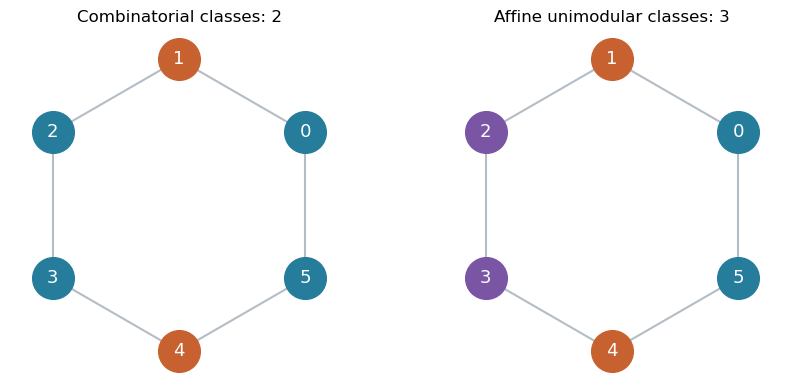

In [20]:
assert [5,4,3,2,1,0] in uni_symmetry["permutations"]
assert comb_symmetry["colored_structure"] == "C2 x C2"
assert uni_symmetry["colored_structure"] == "C2"
import matplotlib.pyplot as plt
from math import cos, sin, pi
fig, axes = plt.subplots(1,2,figsize=(9,4))
positions = {i:(cos(pi/6+i*pi/3),sin(pi/6+i*pi/3)) for i in range(6)}
palette = ["#267c9b","#c76230","#7955a4"]
for ax,groups,title in zip(axes,[comb_groups,uni_groups],
        ["Combinatorial classes: 2","Affine unimodular classes: 3"]):
    colors = {v:j for j,g in enumerate(groups) for v in g}
    for a,b in catalogue["edges"]:
        ax.plot([positions[a][0],positions[b][0]],[positions[a][1],positions[b][1]],
                color="#b4bdc5",zorder=1)
    for v,(x,y) in positions.items():
        ax.scatter([x],[y],s=900,color=palette[colors[v]],zorder=2)
        ax.text(x,y,str(v),ha="center",va="center",color="white",fontsize=13)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    ax.set_xlim(-1.16,1.16); ax.set_ylim(-1.20,1.20)
fig.tight_layout()
plt.show()

## Export the verification
Save all generated inequalities, paths, matrices, partitions, affine maps, normal
forms and colored-group permutations. The export states whether the optional
all-edge geometric check ran. Full f-vectors are not claimed for every seed.

In [21]:
report = dict(status="complete",kind=KIND,weight="2rho",sage_version=SAGE_VERSION,
    seed_count=N,edge_count=int(G.size()),coordinate_convention="column vectors",
    all_seed_matrix_edges_verified=True,geometric_directed_edges_checked=int(geometric_edges_checked),
    seeds=[dict(seed,H=verify.h_rows(P),vertex_count=int(P.n_vertices()),
                facet_count=int(P.n_facets())) for seed,P in zip(catalogue["seeds"],polytopes)],
    directed_edges=catalogue["directed_edges"],edges=catalogue["edges"],
    combinatorial=combinatorial,affine_unimodular=unimodular,
    combinatorial_symmetry=comb_symmetry,affine_unimodular_symmetry=uni_symmetry)
verify.save_json(OUTPUT/"verification.json",report)
print("Saved:", OUTPUT/"verification.json")

Saved: /mnt/c/Users/lej14/Dropbox/My/Sage/2024_Jeongsoo/A4_B2_reproducible_verification/verification-output/B2-reader-run/verification.json


## Optional: volumes and other weights
At $2\rho$, all six volumes are $16$, or $384$ after multiplication by $4!$.
For positive integral weight $(a,b)$ **in C2 numbering**, the formula is
$ab(a+b)(2a+b)/6$. The corresponding B2 coefficients are $(b,a)$.
The cell below replays the paths with the original weight-dependent constants.
It does not assert that the two classifications remain unchanged for other weights.

In [22]:
volumes = [P.volume() for P in polytopes]
assert volumes == [16]*6
print("Volumes at 2rho:", volumes)
print("Normalized volumes:", [factorial(4)*v for v in volumes])
a,b = 1,2  # C2 weight coordinates
other_weight = [verify.b2_weight_polytope(catalogue,i,a,b) for i in range(6)]
expected = QQ(a*b*(a+b)*(2*a+b))/6
assert all(P.volume() == expected for P in other_weight)
print("C2 weight:", (a,b), "| B2 weight:", (b,a))
print("All six volumes:", [P.volume() for P in other_weight])

Volumes at 2rho: [16, 16, 16, 16, 16, 16]
Normalized volumes: [384, 384, 384, 384, 384, 384]
C2 weight: (1, 2) | B2 weight: (2, 1)
All six volumes: [4, 4, 4, 4, 4, 4]


## References and provenance
- [Original Hong–Kim–Lee notebooks](https://github.com/eunjeonglee-math/flag_NOpolytopes).
- [Fujita–Oya] Naoki Fujita and Hironori Oya, Newton–Okounkov polytopes of Schubert varieties arising from cluster structures, Transactions of the American Mathematical Society, Series B 12 (2025), 910–973. (https://doi.org/10.1090/btran/231) 
- [Sage lattice normal forms](https://doc.sagemath.org/html/en/reference/discrete_geometry/sage/geometry/lattice_polytope.html).
- [Sage combinatorial isomorphism](https://doc.sagemath.org/html/en/reference/discrete_geometry/sage/geometry/polyhedron/base4.html).

Copyright © Shin Hong, Jeongsoo Kim, Eunjeong Lee.
Prepared with assistance from ChatGPT.